# COMP8410 Advanced Topic in Artificial Intelligence

# Notebook 2 - Design Generation (Which AI model generates better K-pop comeback merchandise artwork?)

### Introduction

This notebook will compares AI image generation models for designing merchandise for the next K-pop comeback, leading to which model will suit mostly.

Consequently, it evaluates:

* **Prompt alignment** – how closely the artwork follows the comeback concept (theme, colours, motif and product type).
* **Design quality** – the visual quality and print-readiness of the artwork.
* **Style consistency** – whether all products in one collection share one visual style.
* **Efficiency** – generation time, GPU memory and cost.
* **Legal considerations** – commercial licensing and intellectual property risk.

These aspects show which model is more suitable for producing merchandise artwork for a K-pop comeback.

> The rising colours and product types from **Notebook 1 - Trend Analysis** guide the concept briefs used here.

| | System A - Standard System Overview | System B - Global System Overview | Baseline |
|---|---|---|---|
| Model | **Lumina-Image-2.0** (Alpha-VLLM, 2025) | **Stable Diffusion XL Base 1.0** (Stability AI, 2023) | **Stable Diffusion 1.5 + StyleAligned** (Hertz et al., CVPR 2024) |
| Architecture | 2B **flow-matching** diffusion transformer | 3.5B latent **diffusion** UNet (noise prediction) | UNet diffusion with shared self-attention and AdaIN |


### Dataset
Comeback concept briefs for the fictional K-pop group will come from **Design Concept.md** file, which I designed by myself and use it as references.

> The purpose that I decide to cretae my own design due to rights and avoid to use official entertainment information.

* Each brief combines a theme, colours, a motif and a merchandise product type.
* Products include from **Notebook 1_Trend_Analysis.ipynb** result.
* System A, System B and the baseline receive exactly the same briefs.
* No real artists, logos or album artwork are used, avoiding intellectual property and likeness risks which relying to overall knowledge that learn from COMP8410 classes and lectures

### Linked with COMP8410 Knowledge
* Week 10 - Flow Matching vs Diffusion
* Week 2–3 - StyleAligned and Diffusion-based image editing


**References**
- Hertz, A., Voynov, A., Fruchter, S., & Cohen-Or, D. (2024). Style aligned image generation via shared attention. *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*. https://multisearch.mq.edu.au/permalink/61MACQUARIE_INST/1gnm2jp/cdi_ieee_primary_10657939
- Podell, D., English, Z., Lacey, K., Blattmann, A., Dockhorn, T., Müller, J., Penna, J., & Rombach, R. (2023). SDXL: Improving latent diffusion models for high-resolution image synthesis. *International Conference on Learning Representations (ICLR)*. https://multisearch.mq.edu.au/permalink/61MACQUARIE_INST/1gnm2jp/cdi_arxiv_primary_2307_01952
- Qin, Q., et al. (2025). *Lumina-Image 2.0: A unified and efficient image generative framework*. arXiv. https://multisearch.mq.edu.au/permalink/61MACQUARIE_INST/1gnm2jp/cdi_ieee_primary_11444580
- Alpha-VLLM. (2025). *Lumina-Image-2.0* [Model]. Hugging Face. https://huggingface.co/Alpha-VLLM/Lumina-Image-2.0
- Stability AI. (2023). *Stable Diffusion XL Base 1.0* [Model]. Hugging Face. https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0

# 1. Import Libraries and Set-up

In [1]:
# Shared settings: identical in every notebook (if you change one, change all) 
from pathlib import Path
import os, sys, json, time, random, platform, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# Experiment Settings for seed
SEED = 42


SYSTEMS = {"A": "Standard System Overview", "B": "Global System Overview"}

**GPU Checking**
* Cost estimation for computing unit and GPU type
* All of the price references and Google Colab Information in **ENV_SETUP.ipynb**

In [2]:
COLAB_PRICE_PER_UNIT_USD = 9.99 / 100

COLAB_UNITS_PER_HOUR_BY_GPU = {"T4": 1.19, "L4": 1.71, "A100": 5.40}


# GPU Detection
try:

    import torch

    _gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

except ImportError:

    _gpu = "CPU"


# Compute the approximate GPU cost per hour in USD
GPU_HOURLY_USD = next(
    (u for k, u in COLAB_UNITS_PER_HOUR_BY_GPU.items() if k in _gpu), 0.0 ) * COLAB_PRICE_PER_UNIT_USD

In [3]:
#  Random Seed Function 
def set_seed(seed: int = SEED) -> None:

    
    random.seed(seed)

    np.random.seed(seed)

    try:
        import torch

        torch.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)

    except ImportError:
        
        pass

In [4]:
#  Device Detection Function 


def get_device() -> str:

    try:
        import torch

        if torch.cuda.is_available():

            return "cuda"

    except ImportError:
        pass

    return "cpu"



set_seed()


print(
    f"device: {get_device()} | "
    f"GPU: {_gpu} ≈ US${GPU_HOURLY_USD:.3f}/hour"
)

device: cuda | GPU: NVIDIA A100-SXM4-40GB ≈ US$0.539/hour


**Helper Function**

This will help me to check about run metadata (Dataset), timing, outcomes, which will use in all pairs model

So there is mainly feature:
* Check GPU 
* Model management
* Saved program environment
* GPU memory setuo
* Timimg measure
* Save final experiment result

In [5]:
# GPU Type and Capability
def gpu_dtype():

    import torch

    if torch.cuda.is_available():

        if torch.cuda.get_device_capability()[0] >= 8:
            return torch.bfloat16
        else:
            return torch.float16

    return torch.float32

In [6]:
# Transformers Output from AI model to Tensor Function - Model Management
def as_tensor(out):

    """get_*_features returns a tensor in transformers 4.x; newer versions may wrap it in an output object."""

    if hasattr(out, "pooler_output") and out.pooler_output is not None:

        return out.pooler_output

    if hasattr(out, "image_embeds"):
        
        return out.image_embeds

    if hasattr(out, "text_embeds"):

        return out.text_embeds

    return out if hasattr(out, "shape") else out[0]

In [7]:
# Store Environment Information Function 

def env_info():

    """Saved inside every result file as evidence of when and where it was produced."""


    info = {

        "timestamp_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),

        "python": platform.python_version(),

        "os": platform.platform()

    }

    for pkg in ("torch", "transformers", "diffusers", "torch_geometric"):

        try:

            info[pkg] = __import__(pkg).__version__

        except Exception:

            info[pkg] = None

    try:

        import torch

        info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None


    except Exception:

        info["gpu"] = None

    return info

In [8]:
# Logging Function for GPU Synchronization for Accurate Timing and Checking GPU working

def sync_gpu():

    try:

        import torch

        if torch.cuda.is_available():

            torch.cuda.synchronize()

    except ImportError:

        pass

In [9]:
# Free GPU Memory Function to Avoid Out of Memory Errors

def free_gpu():

    import gc

    gc.collect()

    try:

        import torch

        torch.cuda.empty_cache()

    except ImportError:

        pass

In [10]:

# Timer -> for measuring latency and peak GPU memory usage, leading to performance evaluation and cost analysis of AI models

class Timer:
    #  check model performance from Latency and Peak VRAM


    def __init__(self):
        # Constructor will initialize the Timer object and set default values for latencies and peak VRAM usage.

        self.latencies, self.peak_vram_gb = [], None

        try:
           # start checking GPU
            import torch

            if torch.cuda.is_available():
    
                torch.cuda.reset_peak_memory_stats()

        except ImportError:

            pass




    def add(self, seconds, n_items=1):
        # this will calculate the average time per item and store it in the latencies list for further analysis.

        self.latencies.extend([seconds / n_items] * n_items)


    def finish(self):
        # this function is called after all processing is done to finalize the timing and memory usage data.
        try:

         # check GPU again
            import torch

            if torch.cuda.is_available():

                torch.cuda.synchronize()


                self.peak_vram_gb = torch.cuda.max_memory_allocated() / 1024**3
               # check GPU Memory usage and convert to GB

        except ImportError:

            pass

        return self



    def business(self):

        # this function summarizes the business performance metrics of the AI model to provide insights for business decision-making and cost analysis.

        mean = float(np.mean(self.latencies)) if self.latencies else float("nan")
        # Compute the average latency in seconds for processing each item, and handle cases where there are no latencies recorded by returning NaN.

        return {

            "mean_latency_s": round(mean, 4),


            "p95_latency_s": round(float(np.percentile(self.latencies, 95)), 4) if self.latencies else None,
             # 95th percentile latency, indicating that 95% of the items were processed in this time or less. If there are no latencies recorded, it returns None.

            "gpu_hourly_usd": round(GPU_HOURLY_USD, 4),

            "cost_per_1000_usd": round(mean * 1000 / 3600 * GPU_HOURLY_USD, 4),

            "peak_vram_gb": None if self.peak_vram_gb is None else round(self.peak_vram_gb, 2),
          
        }

In [11]:
# JSON file handling function to manage data that cannot be directly converted to JSON, such as NumPy Scalars or special object types.
def _json_default(o):
    

    return o.item() if hasattr(o, "item") else str(o)

In [12]:
# Save Result Function

# Project folders: relative paths work on both Colab and Windows
ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW = ROOT / "Datasets"
PROCESSED = RAW / "processed"
AMAZON_DIR = RAW / "Amazon2023_Merchandise_Data"
RESULTS = ROOT / "Results"
FIGURES, TABLES, METRICS = RESULTS / "figures", RESULTS / "tables", RESULTS / "metrics"
for _d in (PROCESSED, AMAZON_DIR, FIGURES, TABLES, METRICS):
    _d.mkdir(parents=True, exist_ok=True)


def save_result(task, system, model_id, technical, business,
                governance, notes="", items=None, extra=None):

    records = {

        "task": task,

        "system": system,

        "model_id": model_id,

        "technical": technical,

        "business": business,

        "governance": governance,

        "notes": notes,

        "env": env_info(),

        "extra": extra or {}

    }

    path = METRICS / f"{task}__{system}.json"

    path.write_text(
        json.dumps(
            records,
            indent=2,
            ensure_ascii=False,
            default=_json_default
        ),
        encoding="utf-8"
    )

    if items is not None:

        items.to_csv(
            TABLES / f"{task}__{system}_items.csv",
            index=False
        )

    print("saved", path)

    return records

# 2. Task settings

All settings for this notebook in one place.
`QUICK = True` runs a small sample for testing; set it to `False` for the final results.

**System A uses Lumina-Image-2.0 (flow matching) and System B uses SDXL (diffusion); the baseline is SD 1.5 + StyleAligned. All three generate merchandise artwork from the same ECLYRA concept briefs.**

> The ECLYRA concept briefs (group identity, palettes, moods and prompts) are my own design, created to test the models on a realistic comeback merchandise collection without using any real artist, logo or album artwork.

In [13]:
TASK = "2_Design_Generation"
QUICK = True                          
SEEDS = [42] if QUICK else [42, 7, 2026]
SET_SIZE = 5                          # merch items per ECLYRA comeback 
IMAGE_SIZE = 1024                     # Lumina-Image-2.0 and SDXL are trained at 1024 px; use 768 if memory is short
STEP_SWEEP = [1, 2, 4, 8, 30]         # flow matching vs diffusion
SWEEP_SETS = 1 if QUICK else 3        # number of comebacks used in the step sweep
MODELS = {
    "baseline": {"id": "stable-diffusion-v1-5/stable-diffusion-v1-5", "kind": "sd15_stylealigned", "steps": 30, "guidance": 7.5},
    "A": {"id": "Alpha-VLLM/Lumina-Image-2.0", "kind": "lumina2", "steps": 50, "guidance": 4.0},
    "B": {"id": "stabilityai/stable-diffusion-xl-base-1.0", "kind": "sdxl", "steps": 30, "guidance": 7.0},
}
RUN_SYSTEMS = ["baseline", "A", "B"]
LICENCE_COMMERCIAL_OK = {"baseline": True, "A": True, "B": True}    # Apache 2.0 / OpenRAIL++-M / OpenRAIL-M all allow commercial use
SCORER_ID = "openai/clip-vit-large-patch14"                         # CLIPScore judge, independent of A and B
IMAGE_DIR = PROCESSED / "generated"                                 # full-size images (not committed)

## 3 · Concept briefs (from my design named ECLYRA concepts briefts)

The briefs below are my own design for the fictional girl group **ECLYRA**: three comebacks, each with its own theme, palette and mood, and five merchandise items that must look like one collection. Every system receives exactly the same prompts. Additionally, this prompt below will be adjust from **ECLYRA concepts** and **Result from Notebook 1** which will show strongly alignment.

In [14]:
# ECLYRA CONCEPT BRIEFS -> my own design (Design concept.md)
# Trend items from Notebook 1: item 4 of each comeback is a rising product type (tote bag, hoodie, keyring)
BRIEFS = json.loads(r'''
{
  "group": {
    "name": "ECLYRA",
    "display_name": "ECLYRA",
    "type": "Fictional K-pop girl group",
    "tagline": "Own Your Power. Own Your Life.",
    "brand_palette": ["#0D0D0D", "#6D1A36", "#D8C3A5", "#8A8D91", "#B3122E"],
    "mascot_proxy": "grey_sloth_plushie (DreamBooth dataset)",
    "rules": [
      "All characters are adult women",
      "Strength shown through pose, expression and situation",
      "Confidence and style, no explicit content",
      "Each era has its own palette and mood but the same brand identity",
      "MV, cover, photocard, lightstick and teaser must look like one group",
      "Real city life, avoid surreal fantasy"
    ]
  },
  "negative_prompt": "lowres, blurry, deformed hands, extra fingers, watermark, text artifacts, nsfw, nude, cartoon",
  "comeback": [
    {
      "id": "comeback1",
      "name": "After Hours",
      "album_title": "AFTER HOURS",
      "theme": "The life we live after the world stops watching us: simply being ourselves",
      "palette": ["#0D0D0D", "#6D1A36", "#D8C3A5"],
      "mood": ["calm", "intimate", "self-caring"],
      "scene_prompts": [
        "cinematic music video still, a woman reading a book on a cozy sofa at night, warm lamp light, burgundy and champagne tones",
        "a woman in a silk robe making tea in a quiet apartment kitchen, soft warm light, calm cinematic film still",
        "girl group relaxing together on a living room floor with blankets and books, candles, warm burgundy tones, music video scene",
        "a woman doing her skincare routine in a softly lit bathroom mirror, champagne light, intimate cinematic shot",
        "a woman sitting by a rainy window with a journal and coffee, city lights outside, black and burgundy palette, peaceful music video still"
      ],
      "merch_prompts": [
        "K-pop photocard, cozy at-home portrait, black and burgundy, champagne gold border, product photo",
        "album cover with the title 'AFTER HOURS', black and deep burgundy, minimal elegant typography, studio product shot",
        "minimal lightstick, matte black body with a glowing burgundy core, product photo on white background",
        "minimalist canvas tote bag, matte black with a deep burgundy strap, small champagne gold moon motif, calm elegant design, clean product photography",
        "minimalist quote poster with the exact text 'DND mode: ON. Protect your peace.', black and burgundy background, champagne gold typography, calm nighttime apartment aesthetic, premium editorial design"
      ],
      "set_objects": ["book", "candle", "teacup", "silk robe", "vinyl record", "houseplant", "journal", "reading lamp"]
    },
    {
      "id": "comeback2",
      "name": "No Permission",
      "album_title": "NO PERMISSION",
      "theme": "I don't need permission to be who I am. I make my own decisions",
      "palette": ["#111111", "#C0C5CE", "#8B0000"],
      "mood": ["bold", "powerful", "rebellious"],
      "scene_prompts": [
        "four women in black power suits striding through a glass office corridor at night, chrome reflections, cinematic music video still",
        "a woman on a skyscraper rooftop, wind in her hair, deep red coat, dramatic low angle film still",
        "girl group breaking out of a giant glass box, shards frozen in the air, chrome and red light, music video scene",
        "empty boardroom at night, a woman seated at the head of the table, city lights behind her, powerful cinematic shot",
        "women walking toward the camera in a long mirrored hallway, silver and deep red lighting, bold music video still"
      ],
      "merch_prompts": [
        "metallic chrome photocard with a bold portrait, deep red accent, holographic finish, product photo",
        "album cover with the title 'NO PERMISSION', chrome silver on black, sharp bold typography, studio product shot",
        "geometric lightstick with a faceted chrome shell and red light, product photo on white background",
        "oversized black hoodie with a chrome silver 'NO PERMISSION' print and deep red sleeve stripe, bold streetwear design, clean product photography",
        "motivational quote poster with the exact text 'Be yourself. Trust your vision. Become who you dream of being.', black chrome and deep red palette, bold editorial typography, confident ambitious mood"
      ],
      "set_objects": ["office chair", "glass door", "chrome key", "red stiletto", "briefcase", "skyscraper", "broken chain", "mirror"]
    },
    {
      "id": "comeback3",
      "name": "Pretty On My Terms",
      "album_title": "PRETTY ON MY TERMS",
      "theme": "My beauty. My rules.",
      "palette": ["#B3122E", "#C9CED6", "#F4A6B8"],
      "mood": ["playful", "glamorous", "self-assured"],
      "scene_prompts": [
        "girl group getting ready together in front of a vanity mirror, pink and cherry red lights, playful music video still",
        "women dancing at a house party, digital camera flash, glossy silver and warm pink tones, candid film still",
        "a woman taking a mirror selfie with a vintage digital camera, cherry red dress, glamorous cinematic shot",
        "friends laughing in a photo booth, colorful flash photos, warm pink and silver, music video scene",
        "glamorous night street, women in glossy outfits posing under pink neon, confident cinematic still"
      ],
      "merch_prompts": [
        "glossy K-pop photocard set, fashion portraits, cherry red and warm pink, silver sparkle border, product photo",
        "album cover with the title 'PRETTY ON MY TERMS', cherry red and pink, glossy playful typography, studio product shot",
        "heart-shaped lightstick, glossy cherry red body with a polished silver ring and soft pink light, product photo on white background",
        "heart-shaped acrylic keyring, cherry red and warm pink with a polished silver ring, playful glamorous design, premium product photography on white background",
        "motivational quote poster with the exact text 'Be beautiful in your own way.', cherry red and warm pink background, glossy silver typography, confident beauty editorial aesthetic"
      ],
      "set_objects": ["lipstick", "digital camera", "heart charm", "perfume bottle", "vanity mirror", "glitter heels", "disco ball", "sunglasses"]
    }
  ]
}
''')

NEGATIVE_PROMPT = BRIEFS["negative_prompt"]
INCLUDE_SCENES = False      # True also generates the MV scene prompts (scene_prompts); merch only is the task here
TREND_ITEMS = ["tote bag", "hoodie", "keyring"]   # rising product types from Notebook 1, one per comeback

# BUILD PROMPT TABLE -> one row per prompt; "set" groups the 5 merch items of one comeback
rows = []
for cb in BRIEFS["comeback"]:
    parts = [("merch", cb["merch_prompts"])] + ([("scene", cb["scene_prompts"])] if INCLUDE_SCENES else [])
    for kind, prompt_list in parts:
        for i, prompt in enumerate(prompt_list):
            rows.append({"set": cb["id"], "comeback": cb["name"], "kind": kind, "item": i,
                         "prompt": prompt, "palette": cb["palette"], "mood": ", ".join(cb["mood"]),
                         "trend_item": kind == "merch" and any(t in prompt for t in TREND_ITEMS)})

prompts = pd.DataFrame(rows)
print(f"{BRIEFS['group']['name']}: {prompts['set'].nunique()} comebacks, {len(prompts)} prompts x {len(SEEDS)} seed(s)")
show = prompts[["comeback", "kind", "item", "trend_item", "prompt"]].copy()
show.index = range(1, len(show) + 1)
show

ECLYRA: 3 comebacks, 15 prompts x 1 seed(s)


,comeback,kind,item,trend_item,prompt
1,After Hours,merch,0,False,"K-pop photocard, cozy at-home portrait, black ..."
2,After Hours,merch,1,False,"album cover with the title 'AFTER HOURS', blac..."
3,After Hours,merch,2,False,"minimal lightstick, matte black body with a gl..."
4,After Hours,merch,3,True,"minimalist canvas tote bag, matte black with a..."
5,After Hours,merch,4,False,minimalist quote poster with the exact text 'D...
6,No Permission,merch,0,False,metallic chrome photocard with a bold portrait...
7,No Permission,merch,1,False,"album cover with the title 'NO PERMISSION', ch..."
8,No Permission,merch,2,False,geometric lightstick with a faceted chrome she...
9,No Permission,merch,3,True,oversized black hoodie with a chrome silver 'N...
10,No Permission,merch,4,False,motivational quote poster with the exact text ...


### Concept Brief Result

This table shows the **15 prompts** used by all three systems (3 comebacks × 5 merch items). All prompts are for merchandise design, not music video scenes.

**What is `trend_item`?**

* **True:** The item comes from the rising trends in **Notebook 1**, including a tote bag (After Hours), hoodie (No Permission), and keyring (Pretty On My Terms).
* **False:** The item is part of my original ECLYRA concept, such as photocards, album covers, lightsticks, and quote posters.

**Why I use it**

I use `trend_item` to connect Notebook 1 with Notebook 2. I keep the original colour themes but add one trending product to each comeback.

Since Notebook 1 did not outperform the naive baseline in trend prediction, I use these trends as suggestions rather than fixed decisions.

I also calculate `clip_score_trend_items` to check how well each system generates these trend-based designs.

In [15]:
# Each comeback must have exactly SET_SIZE merch prompts (style consistency is measured per set)
merch_per_set = prompts.query("kind == 'merch'").groupby("set").size()
assert merch_per_set.eq(SET_SIZE).all(), f"each comeback needs {SET_SIZE} merch prompts:\n{merch_per_set}"

# Every comeback in the brief must appear in the prompt table
assert set(prompts["set"]) == {cb["id"] for cb in BRIEFS["comeback"]}, "a comeback is missing"

# Each comeback must include one trend item from Notebook 1 (links trend analysis to design)
trend_per_set = prompts.groupby("set")["trend_item"].sum()
assert trend_per_set.eq(1).all(), f"each comeback needs exactly one trend item:\n{trend_per_set}"

# No empty prompts
assert prompts["prompt"].str.len().gt(0).all(), "empty prompt found"

print("PASSED: briefs ready ->", len(prompts), "prompts,", int(prompts["trend_item"].sum()), "trend items from Notebook 1")

PASSED: briefs ready -> 15 prompts, 3 trend items from Notebook 1


## 4 · Scoring with CLIP

In term of comparison, I use a separate CLIP model to evaluate the outputs from System A, System B, and the baseline. 
*All three systems are evaluated using the same metrics.*

* **CLIPScore:** Measures how well each generated image matches its original prompt using `2.5 × max(cos(image, prompt), 0)` -> A higher score means the image is more closely aligned with the comeback concept.

* **Style consistency:** Measures how similar the designs are across five merchandise items from the same comeback collection. It calculate the average pairwise cosine similarity between their CLIP image embeddings. Higher similarity suggests that the products share a more consistent visual style, which is also the main goal of StyleAligned 

* **Trademark probe:** Checks whether the generated designs resemble existing brand logos. It will measure the percentage of probe images that CLIP associates more strongly with "the official \<brand> logo" than with an original design. A lower percentage suggests less potential trademark similarity, although it does not guarantee that the design is legally safe.

> **Limitation:** CLIP can process only up to 77 text tokens, so longer prompts may be truncated during evaluation. Also, CLIPScore provides an automatic measure of image–text similarity, but it cannot fully assess design quality, print-readiness, or legal risks. Human evaluation is still needed.

Which I will be double check at last again to keep concept human in loop

In [16]:
!pip install transformers diffusers

In [17]:
import torch


# CLIP SCORE -> independent judge for all systems (not one of the models being tested)
class Clip_Scorer:
    def __init__(self, model_id=SCORER_ID):
        from transformers import CLIPModel, CLIPProcessor
        self.model = CLIPModel.from_pretrained(model_id).to(get_device()).eval()
        self.proc = CLIPProcessor.from_pretrained(model_id)

    # normalised image embedding
    def image_emb(self, images):
        inp = self.proc(images=images, return_tensors="pt").to(get_device())
        with torch.no_grad():
            return torch.nn.functional.normalize(as_tensor(self.model.get_image_features(**inp)), dim=-1)

    # normalised text embedding ( 77 tokens; longer prompts are cut)
    def text_emb(self, texts):
        inp = self.proc(text=texts, return_tensors="pt", padding=True, truncation=True, max_length=77).to(get_device())
        with torch.no_grad():
            return torch.nn.functional.normalize(as_tensor(self.model.get_text_features(**inp)), dim=-1)

    # CLIPScore = 2.5 x max(cosine(image, prompt), 0) -> higher = closer to the brief
    def clip_score(self, images, prompts):
        return (2.5 * (self.image_emb(images) * self.text_emb(prompts)).sum(-1).clamp(min=0)).cpu().numpy()

    # Trademark probe -> 1 if the image looks more like a real brand logo than an original design
    def brand_match(self, images, brands):
        hits = []
        for img, b in zip(images, brands):
            te = self.text_emb([f"the official {b} logo", "an original product design with no brand logo"])   
            hits.append(int((self.image_emb([img]) @ te.T).softmax(-1)[0, 0] > 0.5))
        return np.array(hits)


# STYLE CONSISTENCY -> mean cosine similarity between every pair of images in one comeback set
def mean_pairwise_cosine(emb):
    emb = np.asarray(emb, dtype=np.float64)
    emb = emb / np.linalg.norm(emb, axis=1, keepdims=True).clip(min=1e-12)
    iu = np.triu_indices(len(emb), k=1)
    return float((emb @ emb.T)[iu].mean()) if len(emb) > 1 else float("nan")

# 5. Image Generators

This experiment compares three image generation models for K-pop merchandise design.

* **System A - Lumina-Image-2.0:** Uses a flow-matching transformer to turn noise into images by learning a velocity field (W10). It runs with 50 steps and guidance 4.0.
* **System B - SDXL Base 1.0:** Uses latent diffusion with a UNet to remove noise step by step. It runs with 30 steps and guidance 7.0.
* **Baseline - SD 1.5 + StyleAligned:** Uses shared self-attention and AdaIN to keep designs in the same style. The first image acts as a style reference, and the other four items follow its style within the same batch.

All models use the same prompts, ECLYRA negative prompt, and random seed to make the comparison as fair as possible.

In [18]:
!pip install -q diffusers transformers accelerate safetensors

In [19]:

import torch.nn.functional as F


# I use adaptive_instance_norm to match the target features with the reference style.
def adaptive_instance_norm(x, ref, eps=1e-5):
    # Match per-channel mean/std of x (n, L, C) to ref (1, L, C) along the token axis
    mu, sd = x.mean(1, keepdim=True), x.std(1, keepdim=True) + eps
    return (x - mu) / sd * (ref.std(1, keepdim=True) + eps) + ref.mean(1, keepdim=True)


# Then I will share attention across images to keep the merchandise designs in one style.
class SharedAttentionProcessor:
    def __init__(self, enabled=True):
        self.enabled = enabled

    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, temb=None, **kwargs):
        is_cross = encoder_hidden_states is not None
        ctx = encoder_hidden_states if is_cross else hidden_states
        q, k, v = attn.to_q(hidden_states), attn.to_k(ctx), attn.to_v(ctx)
        b, _, dim = q.shape
        h = attn.heads
        split = lambda t: t.view(t.shape[0], -1, h, dim // h).transpose(1, 2)
        if is_cross or not self.enabled or b < 4:
            out = F.scaled_dot_product_attention(split(q), split(k), split(v))
        else:
            outs = []
            for s in (slice(0, b // 2), slice(b // 2, b)):           # unconditional half, conditional half
                qs, ks, vs = q[s], k[s], v[s]
                ref = F.scaled_dot_product_attention(split(qs[:1]), split(ks[:1]), split(vs[:1]))
                n = qs.shape[0] - 1
                k_cat = torch.cat([ks[:1].expand(n, -1, -1), adaptive_instance_norm(ks[1:], ks[:1])], dim=1)
                v_cat = torch.cat([vs[:1].expand(n, -1, -1), vs[1:]], dim=1)
                tgt = F.scaled_dot_product_attention(split(adaptive_instance_norm(qs[1:], qs[:1])), split(k_cat), split(v_cat))
                outs.append(torch.cat([ref, tgt], dim=0))
            out = torch.cat(outs, dim=0)
        out = out.transpose(1, 2).reshape(b, -1, dim).to(q.dtype)
        return attn.to_out[1](attn.to_out[0](out))


# load each model using its own pipeline and memory settings. LOAD GENERATOR -> one pipeline per system; all three are open downloads (no token)
def load_generator(spec):
    dtype = gpu_dtype()                                           # bf16 on L4/A100, fp16 on T4

    if spec["kind"] == "lumina2":                                 # System A: flow-matching transformer
        from diffusers import Lumina2Pipeline
        pipe = Lumina2Pipeline.from_pretrained(spec["id"], torch_dtype=dtype)
        pipe.enable_model_cpu_offload()                           # keeps GPU memory low by moving parts to CPU when idle

    elif spec["kind"] == "sdxl":                                  # System B: latent diffusion UNet
        from diffusers import StableDiffusionXLPipeline
        kw = {"variant": "fp16"} if dtype == torch.float16 else {}
        pipe = StableDiffusionXLPipeline.from_pretrained(spec["id"], torch_dtype=dtype, use_safetensors=True, **kw)
        if dtype == torch.float16:                                # the SDXL VAE overflows in fp16 -> keep it in fp32
            pipe.vae.to(torch.float32)
            pipe.vae.config.force_upcast = True
        pipe.enable_model_cpu_offload()

    else:                                                         # Baseline: SD 1.5 + StyleAligned
        from diffusers import DDIMScheduler, StableDiffusionPipeline
        from diffusers.models.attention_processor import AttnProcessor2_0
        pipe = StableDiffusionPipeline.from_pretrained(spec["id"], torch_dtype=dtype).to(get_device())
        pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
        pipe.unet.set_attn_processor({n: SharedAttentionProcessor() if n.endswith("attn1.processor") else AttnProcessor2_0()
                                    for n in pipe.unet.attn_processors})
    return pipe


#generate images with the same prompts and seed to compare the models fairly. GENERATE -> same prompts, seed and negative prompt for every system (fair comparison)
def generate(pipe, spec, prompts, steps=None, seed=SEED):
    steps = steps or spec["steps"]
    common = {"num_inference_steps": steps, "guidance_scale": spec["guidance"]}

    if spec["kind"] == "sd15_stylealigned":                       # one batch, so the whole set shares attention
        return pipe(list(prompts), negative_prompt=[NEGATIVE_PROMPT] * len(prompts), height=512, width=512,
                    generator=torch.Generator("cpu").manual_seed(seed), **common).images

    extra = {"cfg_trunc_ratio": 0.25, "cfg_normalization": True} if spec["kind"] == "lumina2" else {}   # Lumina model-card settings
    return [pipe(p, negative_prompt=NEGATIVE_PROMPT, height=IMAGE_SIZE, width=IMAGE_SIZE,
                generator=torch.Generator("cpu").manual_seed(seed), **common, **extra).images[0]
            for p in prompts]


**Unit Test of shared setting**

which I will use it to check if result shown it expectedly.

In [20]:

# fake attention layer will use to test StyleAligned without loading the actual model.
class FakeAttention(torch.nn.Module):
    def __init__(self, d=16, heads=2):
        super().__init__()
        self.heads = heads
        self.to_q, self.to_k, self.to_v = (torch.nn.Linear(d, d) for _ in range(3))
        self.to_out = torch.nn.ModuleList([torch.nn.Linear(d, d), torch.nn.Dropout(0.0)])


# then compare shared attention with normal attention using the same input.
torch.manual_seed(0)
_attn, _x = FakeAttention(), torch.randn(2 * SET_SIZE, 10, 16)           # SET_SIZE prompts x (uncond, cond), same as ECLYRA sets
_shared, _plain = SharedAttentionProcessor(True)(_attn, _x), SharedAttentionProcessor(False)(_attn, _x)

# output shape stays the same.
assert _shared.shape == _x.shape

# reference images stay unchanged.
assert torch.allclose(_shared[[0, SET_SIZE]], _plain[[0, SET_SIZE]], atol=1e-5), "reference images must not change"

# target images change when sharing attention.
assert not torch.allclose(_shared[1], _plain[1]), "target images must change"

# I check that identical embeddings have a similarity score of 1.
assert abs(mean_pairwise_cosine(np.ones((3, 4))) - 1.0) < 1e-9

print(f"PASS: StyleAligned shared attention ({SET_SIZE} images per set) and style metric shown as expected")


PASS: StyleAligned shared attention (5 images per set) and style metric shown as expected


# 6. Generate Image  and Evaluate The Quality

I generate merchandise images for each ECLYRA comeback set using the same seeds across all models. Then, I evaluate the results and free GPU memory after each model.

* **Generated images:** Save full-size images in `Datasets folder` and sample grids in `Results folder`.
* **Step sweep:** Compare image quality and speed at 1, 2, 4, 8, and 30 steps for Systems A and B.
* **Trend items:** Use CLIPScore to evaluate three products from Notebook 1 result.
* **Human evaluation:** Prepare a 1–5 rating template for prompt alignment, aesthetics, and print-readiness.

In [21]:

from PIL import Image


# this will combine the generated merch images into one grid. CONTACT SHEET -> one image grid per system 
def contact_sheet(images, path, ncol=SET_SIZE):
    w, h = images[0].size
    sheet = Image.new("RGB", (ncol * w, ((len(images) + ncol - 1) // ncol) * h), "white")
    for i, im in enumerate(images):
        sheet.paste(im, ((i % ncol) * w, (i // ncol) * h))
    sheet.thumbnail((2048, 2048)); sheet.save(path)


# CLIP scorer and collect results from each system.
IP_PROBES = None  # Skip trademark testing until probe data is available
scorer = Clip_Scorer() if RUN_SYSTEMS else None
summary, rubric_rows, baseline_clip = {}, [], None
first_set = prompts["set"].iloc[0]

for system in RUN_SYSTEMS:
    spec = MODELS[system]
    pipe = load_generator(spec)
    timer, rows, style = Timer(), [], []

    # generate each comeback set using the selected seed -> every comeback set with every seed
    for seed in SEEDS:
        for set_id, g in prompts.groupby("set", sort=True):
            t0 = time.perf_counter()
            imgs = generate(pipe, spec, g["prompt"].tolist(), seed=seed)
            sync_gpu(); timer.add(time.perf_counter() - t0, len(imgs))

            # Measure prompt alignment and style consistency using CLIP. -> check brieft score and style consistency
            scores = scorer.clip_score(imgs, g["prompt"].tolist())
            style.append(mean_pairwise_cosine(scorer.image_emb(imgs).cpu().numpy()))

            # SAVE images + one row per image for evaluation
            (IMAGE_DIR / system).mkdir(parents=True, exist_ok=True)
            for (_, r), im, s in zip(g.iterrows(), imgs, scores):
                p = IMAGE_DIR / system / f"{set_id}_item{r['item']}_seed{seed}.png"
                im.save(p)
                rows.append({**r.to_dict(), "seed": seed, "system": system,
                             "image_path": str(p.relative_to(ROOT)), "clip_score": float(s)})
                rubric_rows.append({"set": set_id, "item": r["item"], "seed": seed, "system": system,
                                    "image_path": str(p.relative_to(ROOT)),
                                    "on_brief_1to5": "", "aesthetics_1to5": "", "print_ready_1to5": ""})

            # CONTACT SHEET -> first comeback, first seed -> save a sample of each
            if set_id == first_set and seed == SEEDS[0]:
                contact_sheet(imgs, FIGURES / f"{TASK}_{system}_sample_set.png")
    timer.finish()

    # STEP SWEEP  to test how it can be differ sampling steps affect image quality and speed.
    sweep = []
    if system != "baseline":
        for steps in STEP_SWEEP:
            for set_id, g in list(prompts.groupby("set", sort=True))[:SWEEP_SETS]:
                t0 = time.perf_counter()
                imgs = generate(pipe, spec, g["prompt"].tolist(), steps=steps, seed=SEEDS[0])
                sweep.append({"system": system, "steps": steps, "set": set_id,
                              "sec_per_image": (time.perf_counter() - t0) / len(imgs),
                              "clip_score": float(np.mean(scorer.clip_score(imgs, g["prompt"].tolist())))})
        pd.DataFrame(sweep).to_csv(TABLES / f"{TASK}__{system}_step_sweep.csv", index=False)

    #check whether generated images resemble existing brand logos. TRADEMARK PROBE -> check images are never published)
    ip_rate = float("nan")
    if system != "baseline" and IP_PROBES is not None:
        probe = [generate(pipe, spec, [p])[0] for p in IP_PROBES["prompt"]]
        ip_rate = float(scorer.brand_match(probe, IP_PROBES["brand"].tolist()).mean())

    # SAVE RESULTS
    items = pd.DataFrame(rows)
    clip_mean = float(items["clip_score"].mean())
    clip_trend = float(items.loc[items["trend_item"], "clip_score"].mean())     # trend items from Notebook 1
    baseline_clip = clip_mean if system == "baseline" else baseline_clip
    save_result(TASK, system, spec["id"],
                technical={"clip_score": clip_mean, "clip_score_trend_items": clip_trend,
                           "style_consistency": float(np.nanmean(style)), "clip_score_baseline": baseline_clip},
                business=timer.business(),
                governance={"licence_commercial_ok": LICENCE_COMMERCIAL_OK[system], "ip_probe_match_rate": ip_rate},
                items=items, extra={"step_sweep": sweep},
                notes=f"ECLYRA: {prompts['set'].nunique()} comebacks x {SET_SIZE} merch items x {len(SEEDS)} seed(s), {spec['steps']} steps")
    summary[system] = {"clip_score": clip_mean, "clip_score_trend_items": clip_trend,
                       "style_consistency": float(np.nanmean(style)), **timer.business(), "ip_probe_match_rate": ip_rate}
    del pipe; free_gpu()

# export the scoring template and compare the final results.
pd.DataFrame(rubric_rows).to_csv(TABLES / f"{TASK}__rubric_template.csv", index=False)
pd.DataFrame(summary).T.round(3)


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

... (105 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

saved /content/Results/metrics/2_Design_Generation__B.json


,clip_score,clip_score_trend_items,style_consistency,mean_latency_s,p95_latency_s,gpu_hourly_usd,cost_per_1000_usd,peak_vram_gb,ip_probe_match_rate
baseline,0.687,0.722,0.493,0.852,1.183,0.54,0.128,6.68,NaN
A,0.729,0.679,0.462,20.779,21.229,0.54,3.114,6.94,NaN
B,0.738,0.742,0.434,7.627,7.864,0.54,1.143,6.80,NaN


**UNIT_TEST**
for checking all brieft produced a full while shown score set for every system

In [22]:

# Check that each system saves the correct number of images and scores.
for system in RUN_SYSTEMS:
    items = pd.read_csv(TABLES / f"{TASK}__{system}_items.csv")

    # Check one image per prompt and seed.
    expected = len(prompts) * len(SEEDS)
    assert len(items) == expected, f"{system}: {len(items)} images, expected {expected} ({len(prompts)} prompts x {len(SEEDS)} seeds)"

    # Check that CLIPScore stays within the expected range.
    assert items["clip_score"].between(0, 2.5).all(), f"{system}: CLIP-S out of range"

    # Check that all generated image files exist.
    assert all((ROOT / p).exists() for p in items["image_path"]), f"{system}: missing image files"

print("PASSED: complete image sets for", RUN_SYSTEMS)



PASSED: complete image sets for ['baseline', 'A', 'B']


# 7. Sample sets and quality vs steps (Images)

System baseline


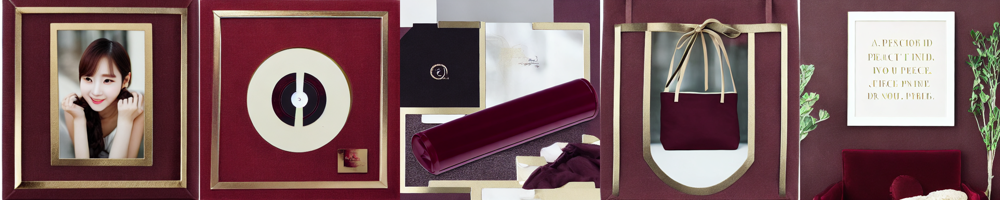

System A


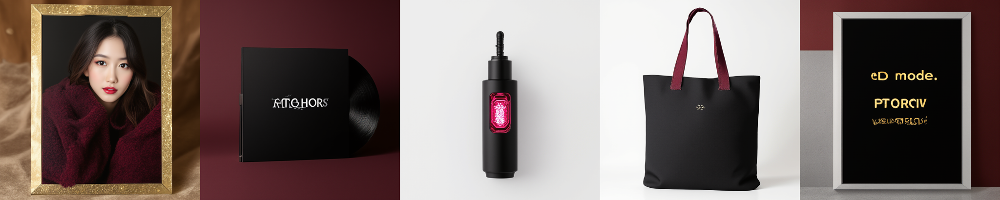

System B


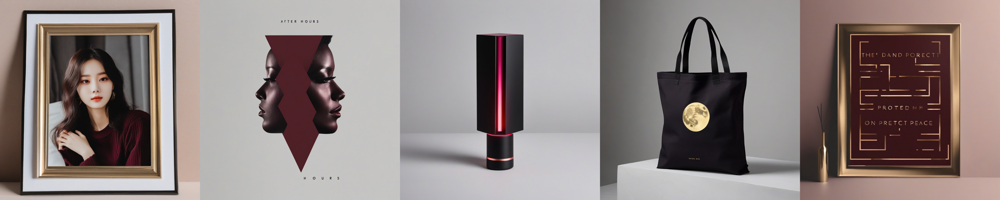

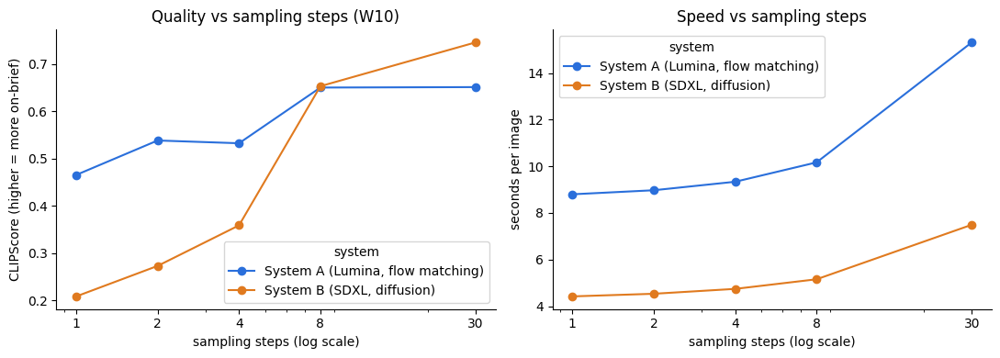

In [23]:

import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage

# Display the first comeback set from each system.
for s in RUN_SYSTEMS:
    p = FIGURES / f"{TASK}_{s}_sample_set.png"
    if p.exists():
        print("System", s); display(ShowImage(filename=str(p), width=900))

# Then it will compare image quality and generation speed at different sampling steps.
# Result will come as figure from plt
sweeps = [pd.read_csv(f) for f in TABLES.glob(f"{TASK}__*_step_sweep.csv")]
if sweeps:
    sw = pd.concat(sweeps)
    names = {"A": "System A (Lumina, flow matching)", "B": "System B (SDXL, diffusion)"}
    colours = {names["A"]: "#2a6fdb", names["B"]: "#e07a1f"}

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, col, label in zip(axes, ["clip_score", "sec_per_image"], ["CLIPScore (higher = more on-brief)", "seconds per image"]):
        data = sw.groupby(["system", "steps"])[col].mean().unstack(0).rename(columns=names)
        data.plot(ax=ax, marker="o", logx=True, color=colours)
        ax.set_xticks(STEP_SWEEP); ax.set_xticklabels(STEP_SWEEP)
        ax.set_xlabel("sampling steps (log scale)"); ax.set_ylabel(label)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_title("Quality vs sampling steps (W10)")
    axes[1].set_title("Speed vs sampling steps")
    plt.tight_layout(); plt.savefig(FIGURES / f"{TASK}_step_sweep.png", dpi=200); plt.show()


System baseline - After Hours


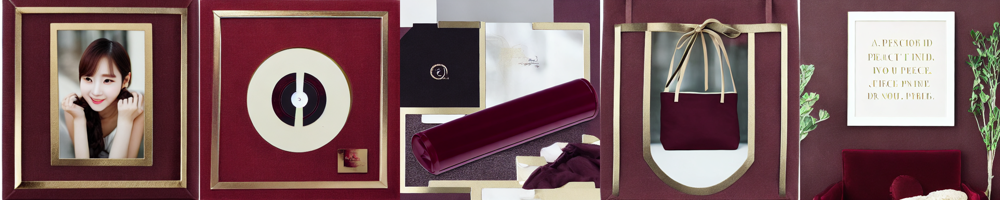

System baseline - No Permission


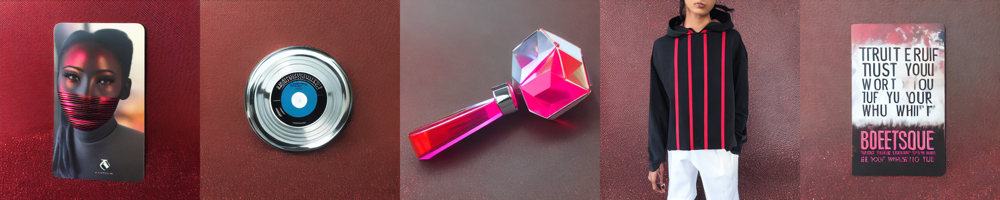

System baseline - Pretty On My Terms


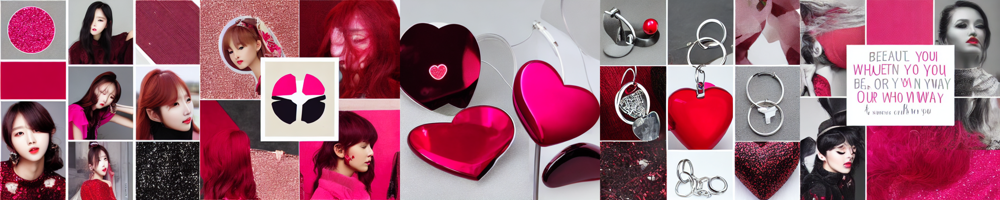

System A - After Hours


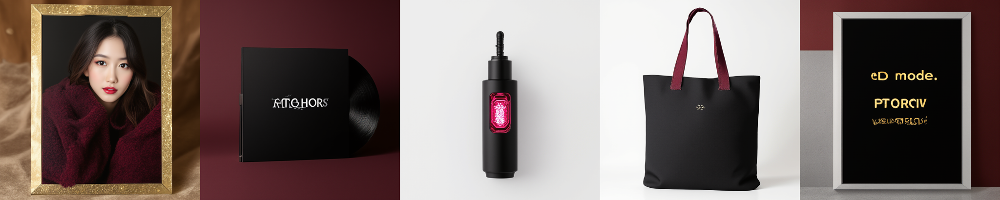

System A - No Permission


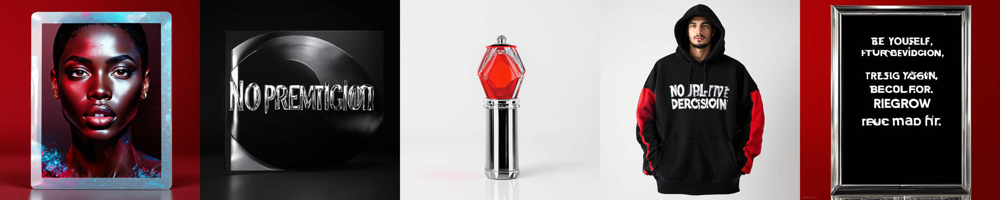

System A - Pretty On My Terms


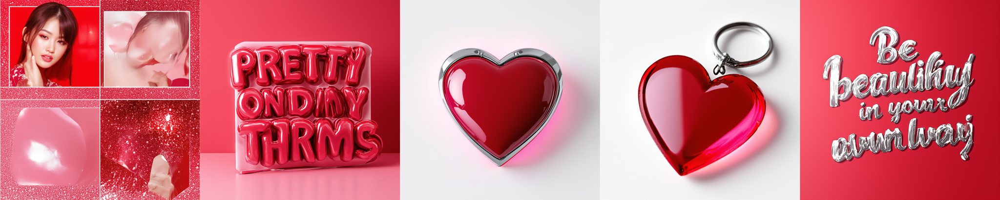

System B - After Hours


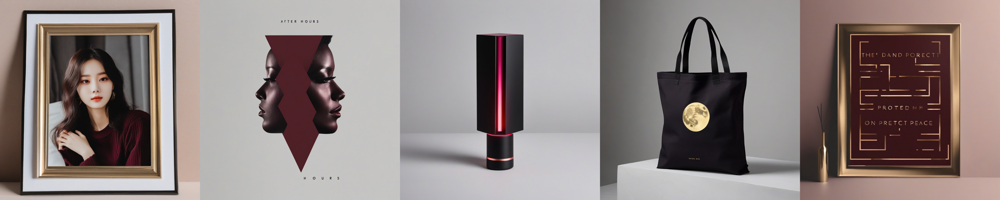

System B - No Permission


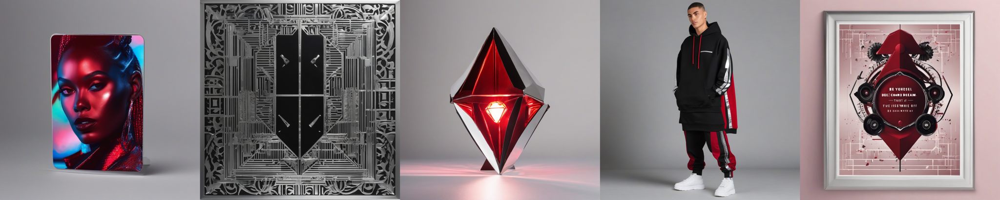

System B - Pretty On My Terms


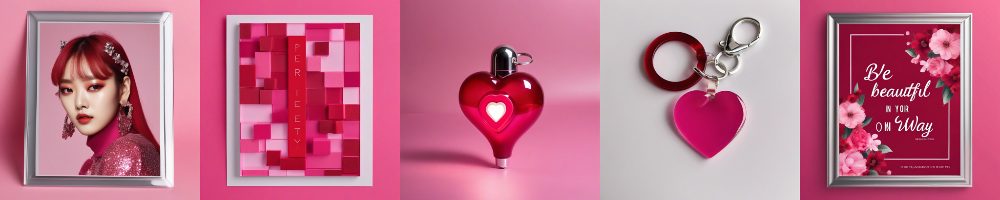

In [24]:
# Show all merch sets: every comeback from every system
for system in RUN_SYSTEMS:
    for set_id, g in prompts.groupby("set", sort=True):
        paths = sorted((IMAGE_DIR / system).glob(f"{set_id}_item*_seed{SEEDS[0]}.png"))
        sheet = FIGURES / f"{TASK}_{system}_{set_id}.png"
        contact_sheet([Image.open(p).convert("RGB") for p in paths], sheet)
        print(f"System {system} - {g['comeback'].iloc[0]}")
        display(ShowImage(filename=str(sheet), width=900))

# 10. Import all result from Google Drive

Due to I used Google Colab Extention to do a Computer unit so all result will collect in google drive.
Then I do need to do this part for download all result in zip file and manually paste in result file

In [25]:
from pathlib import Path

print("Working directory:", Path.cwd())
print("Results path:", RESULTS.resolve())
print("Results exists:", RESULTS.exists())

print("\nCSV files found:")
csv_files = list(RESULTS.rglob("*.csv"))

for f in csv_files:
    print(f.resolve())

print(f"\nTotal CSV files: {len(csv_files)}")

Working directory: /content
Results path: /content/Results
Results exists: True

CSV files found:
/content/Results/tables/2_Design_Generation__B_items.csv
/content/Results/tables/2_Design_Generation__baseline_items.csv
/content/Results/tables/2_Design_Generation__A_items.csv
/content/Results/tables/2_Design_Generation__A_step_sweep.csv
/content/Results/tables/2_Design_Generation__B_step_sweep.csv
/content/Results/tables/2_Design_Generation__rubric_template.csv

Total CSV files: 6


In [26]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [27]:
import shutil
from pathlib import Path

# Create ZIP from the Results folder
source_folder = RESULTS
source = Path("/content/Results.zip")
destination = Path("/content/drive/MyDrive/Results.zip")

# Check the Results folder
assert source_folder.exists(), "Results folder not found"

# Create ZIP file
shutil.make_archive(
    str(source.with_suffix("")),
    "zip",
    root_dir=source_folder
)

# Check ZIP file before copying
assert source.exists(), "Results.zip not found"

# Copy ZIP to Google Drive
assert destination.parent.exists(), "Google Drive is not mounted"
shutil.copy2(source, destination)

print("Copy successful:", destination.exists())
print("Saved to:", destination)
print("Size (MB):", round(destination.stat().st_size / 1024**2, 2))

Copy successful: True
Saved to: /content/drive/MyDrive/Results.zip
Size (MB): 12.44


# 11. Conclusion
All results in one place and the better system for each dimension.

In [28]:
# LOAD SAVED RESULTS -> one JSON file per system
records = {s: json.loads((METRICS / f"{TASK}__{s}.json").read_text(encoding="utf-8")) for s in RUN_SYSTEMS}

# SUMMARY TABLE
rows = {
    ("Technical", "CLIPScore (higher = more on-brief)"):      {s: r["technical"]["clip_score"] for s, r in records.items()},
    ("Technical", "CLIPScore - trend items (Notebook 1)"):    {s: r["technical"]["clip_score_trend_items"] for s, r in records.items()},
    ("Technical", "Style consistency (higher = one look)"):   {s: r["technical"]["style_consistency"] for s, r in records.items()},
    ("Business", "Seconds per image (lower = better)"):       {s: r["business"]["mean_latency_s"] for s, r in records.items()},
    ("Business", "Cost per 1,000 images (USD)"):              {s: r["business"]["cost_per_1000_usd"] for s, r in records.items()},
    ("Business", "Peak GPU memory (GB)"):                     {s: r["business"]["peak_vram_gb"] for s, r in records.items()},
    ("Governance", "Commercial licence OK"):                  {s: r["governance"]["licence_commercial_ok"] for s, r in records.items()},
}
summary_table = pd.DataFrame(rows).T
summary_table.columns = [f"{s} ({MODELS[s]['id'].split('/')[-1]})" for s in RUN_SYSTEMS]
display(summary_table)
summary_table.to_csv(TABLES / f"{TASK}__summary.csv")

# WINNER PER DIMENSION (System A vs System B)
ab = [s for s in RUN_SYSTEMS if s != "baseline"]
better = {
    "On-brief quality (CLIPScore)": max(ab, key=lambda s: records[s]["technical"]["clip_score"]),
    "Trend items (CLIPScore)": max(ab, key=lambda s: records[s]["technical"]["clip_score_trend_items"]),
    "Style consistency": max(ab, key=lambda s: records[s]["technical"]["style_consistency"]),
    "Speed / cost": min(ab, key=lambda s: records[s]["business"]["cost_per_1000_usd"]),
}
print("Better system per dimension (A vs B):")
for k, s in better.items():
    print(f"  {k}: System {s}")

# BASELINE CHECK -> does each system beat SD 1.5 + StyleAligned on CLIPScore?
base = records["baseline"]["technical"]["clip_score"]
for s in ab:
    c = records[s]["technical"]["clip_score"]
    print(f"System {s}: CLIPScore {c:.3f} vs baseline {base:.3f} -> {'beats baseline' if c > base else 'does not beat baseline'}")

baseline (stable-diffusion-v1-5)  \
Technical  CLIPScore (higher = more on-brief)                            0.687349   
           CLIPScore - trend items (Notebook 1)                          0.722389   
           Style consistency (higher = one look)                         0.493429   
Business   Seconds per image (lower = better)                              0.8523   
           Cost per 1,000 images (USD)                                     0.1277   
           Peak GPU memory (GB)                                              6.68   
Governance Commercial licence OK                                             True   

                                                 A (Lumina-Image-2.0)  \
Technical  CLIPScore (higher = more on-brief)                0.728945   
           CLIPScore - trend items (Notebook 1)              0.678937   
           Style consistency (higher = one look)             0.461774   
Business   Seconds per image (lower = better)                 20.7789   
           Cost per 1,000 images (USD)                         3.1137   
           Peak GPU memory (GB)                                  6.94   
Governance Commercial licence OK                                 True   

                                                 B (stable-diffusion-xl-base-1.0)  
Technical  CLIPScore (higher = more on-brief)                            0.738388  
           CLIPScore - trend items (Notebook 1)                          0.742425  
           Style consistency (higher = one look)                         0.433737  
Business   Seconds per image (lower = better)                               7.627  
           Cost per 1,000 images (USD)                                     1.1429  
           Peak GPU memory (GB)                                               6.8  
Governance Commercial licence OK                                             True

Better system per dimension (A vs B):
  On-brief quality (CLIPScore): System B
  Trend items (CLIPScore): System B
  Style consistency: System A
  Speed / cost: System B
System A: CLIPScore 0.729 vs baseline 0.687 -> beats baseline
System B: CLIPScore 0.738 vs baseline 0.687 -> beats baseline


---
# Live DEMO Section

I need to do this section due to my overall code consume over 1 hours execution which over 5 mins execution requirement 

In [29]:

scorer = Clip_Scorer() if "Clip_Scorer" in globals() else Clip_Scorer()
DEMO_PIPES = {s: load_generator(MODELS[s]) for s in RUN_SYSTEMS}
print("Demo ready:", list(DEMO_PIPES))

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Demo ready: ['baseline', 'A', 'B']


LIVE DEMO - Notebook 2: Design Generation (all ECLYRA merch)

INPUT: After Hours | mood: calm, intimate, self-caring | palette: #0D0D0D, #6D1A36, #D8C3A5


  0%|          | 0/30 [00:00<?, ?it/s]

  Baseline (SD 1.5 + StyleAligned)     5 images |   0.7s per image | mean CLIPScore 0.675


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  System B (SDXL, diffusion)           5 images |   2.4s per image | mean CLIPScore 0.702


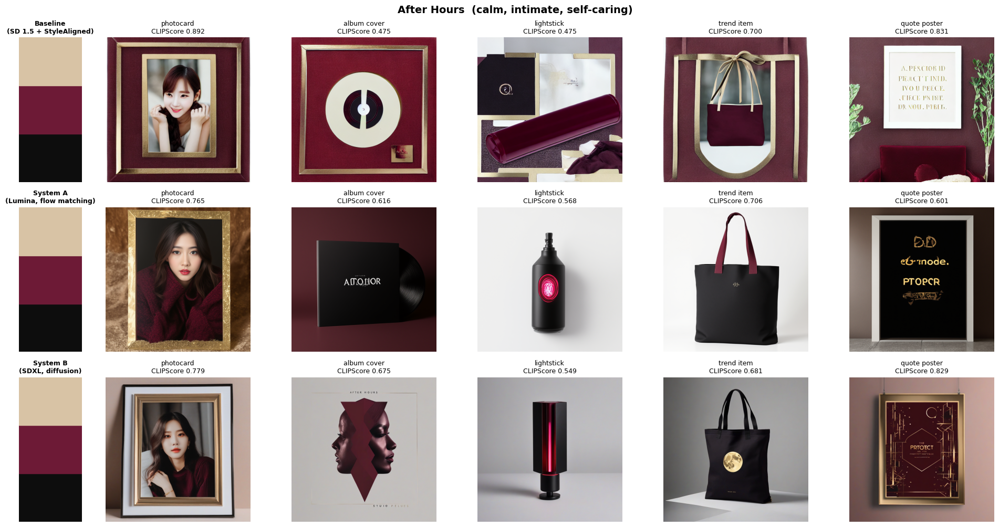


INPUT: No Permission | mood: bold, powerful, rebellious | palette: #111111, #C0C5CE, #8B0000


  0%|          | 0/30 [00:00<?, ?it/s]

  Baseline (SD 1.5 + StyleAligned)     5 images |   0.7s per image | mean CLIPScore 0.696


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  System B (SDXL, diffusion)           5 images |   2.4s per image | mean CLIPScore 0.721


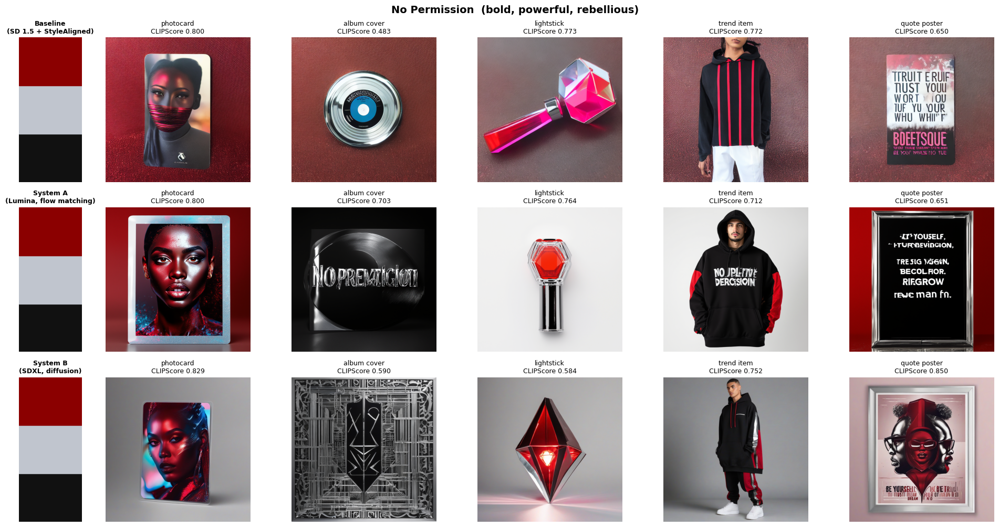


INPUT: Pretty On My Terms | mood: playful, glamorous, self-assured | palette: #B3122E, #C9CED6, #F4A6B8


  0%|          | 0/30 [00:00<?, ?it/s]

  Baseline (SD 1.5 + StyleAligned)     5 images |   0.7s per image | mean CLIPScore 0.692


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  System B (SDXL, diffusion)           5 images |   2.4s per image | mean CLIPScore 0.790


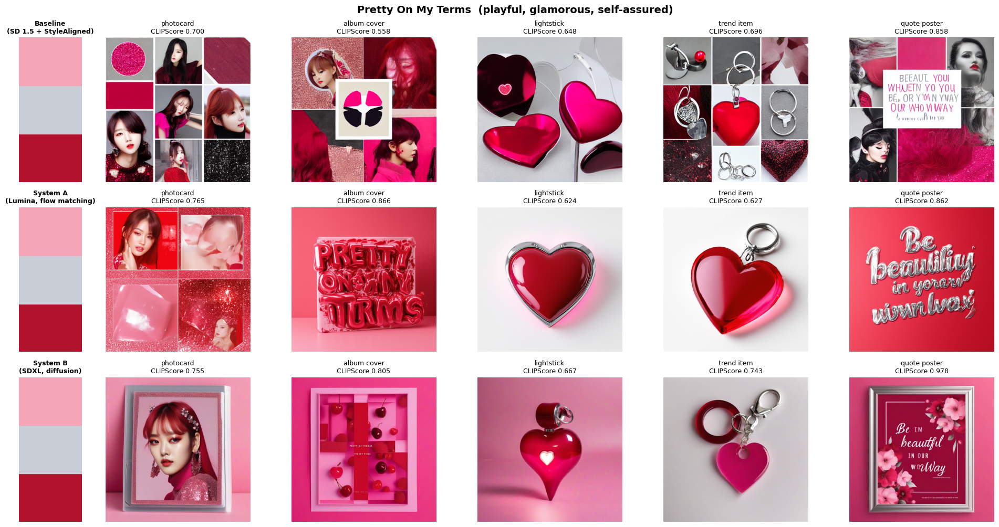


OUTPUT


,mean CLIPScore,seconds per image
Baseline (SD 1.5 + StyleAligned),0.687,0.698
"System A (Lumina, flow matching)",0.709,7.380
"System B (SDXL, diffusion)",0.738,2.425


Highest average CLIP Score -> System B (SDXL, diffusion)
Note: demo mode uses fewer steps for system A & system B -> full-step results are in Section 6.


In [30]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

print("LIVE DEMO - Notebook 2: Design Generation (all ECLYRA merch)\n")

# SETUP
FAST_DEMO = True       
names = {"baseline": "Baseline (SD 1.5 + StyleAligned)", "A": "System A (Lumina, flow matching)", "B": "System B (SDXL, diffusion)"}
item_names = ["photocard", "album cover", "lightstick", "trend item", "quote poster"]
systems = list(DEMO_PIPES)

for s in systems:
    if hasattr(DEMO_PIPES[s], "remove_all_hooks"):
        DEMO_PIPES[s].remove_all_hooks()
    DEMO_PIPES[s] = DEMO_PIPES[s].to("cuda")

def demo_spec(s):
    spec = dict(MODELS[s])
    if FAST_DEMO and s == "A": spec["steps"] = 30
    if FAST_DEMO and s == "B": spec["steps"] = 20
    return spec

results = []      # show in 1 row ->comeback, system, item, image, seconds, clip_score
for set_id, g in prompts.groupby("set", sort=True):
    g = g.sort_values("item")
    comeback, palette, mood = g["comeback"].iloc[0], g["palette"].iloc[0], g["mood"].iloc[0]

    # INPUT : the comeback brief
    print(f"INPUT: {comeback} | mood: {mood} | palette: {', '.join(palette)}")

    # MODELS : every system designs the whole 5-item collection with the same seed
    images = {}
    for s in systems:
        t0 = time.perf_counter()
        imgs = generate(DEMO_PIPES[s], demo_spec(s), g["prompt"].tolist(), seed=SEEDS[0])   
        sync_gpu()
        sec = (time.perf_counter() - t0) / len(imgs)
        scores = scorer.clip_score(imgs, g["prompt"].tolist())
        images[s] = imgs
        for i, (im, sc) in enumerate(zip(imgs, scores)):
            results.append((comeback, s, i, sec, float(sc)))
        print(f"  {names[s]:36s} {len(imgs)} images | {sec:5.1f}s per image | mean CLIPScore {scores.mean():.3f}")

    # OUTPUT : one figure per comeback: palette + 5 items for each system
    fig, axes = plt.subplots(len(systems), 1 + len(g), figsize=(3.2 * (1 + len(g)), 3.4 * len(systems)),
                             gridspec_kw={"width_ratios": [0.35] + [1] * len(g)}, squeeze=False)
    for row, s in enumerate(systems):
        ax = axes[row, 0]
        for j, colour in enumerate(palette):
            ax.add_patch(Rectangle((0, j), 1, 1, color=colour))
        ax.set_xlim(0, 1); ax.set_ylim(0, len(palette)); ax.axis("off")
        ax.set_title(names[s].replace(" (", "\n("), fontsize=9, fontweight="bold")
        for col, im in enumerate(images[s]):
            ax = axes[row, col + 1]
            ax.imshow(im); ax.axis("off")
            sc = next(x[4] for x in results if x[0] == comeback and x[1] == s and x[2] == col)
            ax.set_title(f"{item_names[col]}\nCLIPScore {sc:.3f}", fontsize=9)
    fig.suptitle(f"{comeback}  ({mood})", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()
    print()

# SUMMARY 
table = pd.DataFrame(results, columns=["comeback", "system", "item", "seconds", "clip_score"])
summary = table.groupby("system")[["clip_score", "seconds"]].mean().reindex(systems).round(3)
summary.columns = ["mean CLIPScore", "seconds per image"]
summary.index = [names[s] for s in summary.index]
print("OUTPUT")
display(summary)
print(f"Highest average CLIP Score -> {summary['mean CLIPScore'].idxmax()}")
if FAST_DEMO:
    print("Note: demo mode uses fewer steps for system A & system B -> full-step results are in Section 6.")